# СОСТАВ КОМАНДЫ № 11 — КЕЙС № 2

**Тема:** Прогнозирование оттока клиентов телекоммуникационной компании.

| Участник | Роль | Предлагаемая зона ответственности (по роли) |
|---|---|---|
| Майданский Александр Аркадьевич | **TL — Team Lead** | Организация работы команды, планирование задач и сроков, координация подготовки защиты |
| Поляков Александр Алексеевич | **DA/ML — Data Analyst / Machine Learning** | Анализ данных и признаков, участие в разработке и сравнении моделей |
| Волков Владислав Александрович | **TL — Team Lead** | Техническая координация, согласование методологии и интеграция результатов |
| Петракова Юлия Вячеславовна | **DA — Data Analyst** | Исследовательский анализ, визуализация, анализ факторов оттока |
| Сахно Никита Сергеевич | **DA — Data Analyst** | Проверка аналитических гипотез, интерпретация результатов, подготовка выводов |
| Епишов Сергей Владиславович | **ML — Machine Learning** | Обучение и сравнение моделей, валидация, подбор гиперпараметров, сохранение модели |

*Распределение обязанностей приведено по ролям; фактический вклад подтверждается участниками команды.*

### Рабочее окружение и библиотеки
Запуск из VS Code с Python-окружением проекта. Для повторения результатов необходимы `data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv` и `src/data_utils.py`.

In [1]:
from pathlib import Path
import os
import sys

# Локальный путь проекта (при переносе на другой компьютер измените его).
PROJECT_ROOT = Path(r"D:\01_Study\Case_02_Telco_Churn")
if not (PROJECT_ROOT / "src" / "data_utils.py").is_file():
    raise FileNotFoundError(f"Не найден src/data_utils.py в {PROJECT_ROOT}")
if not (PROJECT_ROOT / "data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv").is_file():
    raise FileNotFoundError("Не найден исходный CSV в data/raw")
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("Рабочая папка:", Path.cwd())
print("Python:", sys.executable)
print("Исходные файлы найдены")

Рабочая папка: D:\01_Study\Case_02_Telco_Churn
Python: d:\01_Study\Case_02_Telco_Churn\.venv312\Scripts\python.exe
Исходные файлы найдены


# Предзащита: постановка задачи и первый исследовательский этап

**Команда № 11 · Кейс № 2 · Прогнозирование оттока клиентов телекоммуникационной компании**

**Цель предзащиты:** согласовать постановку задачи, критерии успеха, план исследования и показать уже реализованную часть: загрузку и контроль данных, EDA на train, гипотезы и новые признаки, Pipeline, сравнение масштабирования и baseline.

**Объект:** клиент телекоммуникационной компании. **Цель модели:** оценить вероятность оттока (`Отток`: 1 — ушёл, 0 — остался). Датасет не задаёт горизонт прогноза, поэтому мы не обещаем предсказать уход «в ближайший месяц».

**Практическая постановка:** ранжировать клиентов по риску для приоритетной работы отдела удержания. Бизнес-эффект пока не оценён: стоимость контакта, цена ошибки и эффект удержания требуют отдельной проверки.

**Метрики:** ROC-AUC — основная для ранжирования; Recall — сколько ушедших обнаруживаем; Precision — какая доля отмеченных действительно ушла; F1 — баланс Precision и Recall. Порог и бизнес-целевые значения предлагается согласовать до финальной защиты.

**Схема валидации:** стратифицированный train/test 80/20, 5-fold StratifiedKFold на train, обучаемые преобразования внутри Pipeline; test не используется для разработки и настройки.

**Граница демонстрации:** здесь намеренно **нет** итогового подбора гиперпараметров, Optuna, финальной тестовой оценки, SHAP и выгрузки рисков. Эти разделы запланированы к основной защите. Полный исследовательский ноутбук хранится отдельно.

## Что показываем сейчас и что оставляем на основную защиту

| Критерий оценки | На предзащите | На основной защите |
|---|---|---|
| Постановка задачи и EDA (25) | Цель, объект, метрики, качество данных, сегменты, гипотезы, новые признаки, ★ масштабирование | Проверка гипотез на итоговых экспериментах |
| Валидация (25) | Train/test, стратификация, Pipeline, 5-fold CV, среднее ± std | Независимый test и анализ порога |
| Моделирование (30) | DummyClassifier и LogisticRegression как стартовый baseline | Сравнение ансамблей, Grid/RandomizedSearch, ★ Optuna, SMOTE, ablation |
| Воспроизводимость (20) | Роли команды, фиксированный seed, читаемый код, сохранённые результаты первого этапа | Полный Run All, модельный артефакт и выгрузка |

**Вопросы для согласования с руководителем:** 1) достаточно ли ROC-AUC как главной метрики? 2) нужен ли приоритет Recall и какой уровень ложных тревог допустим? 3) какие бизнес-ограничения важны для списка риска? 4) требуется ли отдельный временной тест, если будут даты наблюдений?

**Статус:** первый этап выполнен; последующие эксперименты в этом файле не демонстрируются. Конкретный вклад участников следует подтвердить командой.

In [2]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, RobustScaler, StandardScaler
from src.data_utils import load_and_clean

RANDOM_STATE = 42
CV_FOLDS = 5
N_JOBS = 2
CV = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
sns.set_theme(style="whitegrid")
PALETTE = {"Остался": "#4c9f70", "Ушёл": "#e4572e"}
CLASS_LABELS = {0: "Остался", 1: "Ушёл"}

### Порядок запуска и границы демонстрации

- Используйте **Restart Kernel and Run All Cells** для проверки воспроизводимости.
- В этой версии применяется **5-fold StratifiedKFold** с `RANDOM_STATE=42`.
- Предобработка обучается внутри `Pipeline` на каждом фолде; независимый Test не используется для выбора модели.
- Здесь показаны EDA, четыре новых признака, сравнение масштабирования и базовые модели. Optuna, подбор гиперпараметров, оценка на Test и SHAP относятся к следующему этапу.
- Для запуска необходимы исходный CSV и модуль `src/data_utils.py`.

## 1. Загрузка данных
Проверяем размер, долю целевого класса, пропуски и дубликаты.

In [3]:
df = load_and_clean()
print(f"Размер данных: {df.shape}")
print(f"Доля ушедших: {df['Отток'].mean():.1%}")
print(f"Пропусков всего: {df.isna().sum().sum()}")
print(f"Совпадений по всем столбцам (без ID): {df.duplicated().sum()}")
display(df.head(3))
# Фиксируем hold-out ДО любого исследовательского анализа.
raw_X = df.drop(columns=["Отток"])
raw_y = df["Отток"]
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    raw_X, raw_y, test_size=0.2, stratify=raw_y, random_state=RANDOM_STATE
)
df_eda_raw = X_train_raw.copy()
df_eda_raw["Отток"] = y_train
print(f"Обучающая выборка: {len(df_eda_raw)}; независимый test: {len(X_test_raw)}")

# Контроль независимости Train/Test (индекс — идентификатор клиента).
assert X_train_raw.index.intersection(X_test_raw.index).empty
assert len(X_train_raw) + len(X_test_raw) == len(df)
assert df_eda_raw.index.equals(X_train_raw.index)
print("Проверка разделения: пройдена")


Размер данных: (7043, 20)
Доля ушедших: 26.5%
Пропусков всего: 0
Совпадений по всем столбцам (без ID): 22


,Пол,Пенсионер,Есть партнёр,Есть иждивенцы,Стаж,Телефония,Несколько линий,Интернет,Онлайн-защита,Облачный бэкап,Защита устройства,Техподдержка,Стриминг ТВ,Стриминг кино,Контракт,Электронный счёт,Способ оплаты,Платёж в месяц,Всего оплачено,Отток
customerID,,,,,,,,,,,,,,,,,,,,
7590-VHVEG,Женский,0,Да,Нет,1,Нет,Нет телефонии,DSL,Нет,Да,Нет,Нет,Нет,Нет,Помесячный,Да,Электронный чек,29.850000,29.850000,0
5575-GNVDE,Мужской,0,Нет,Нет,34,Да,Нет,DSL,Да,Нет,Да,Нет,Нет,Нет,Годовой,Нет,Чек по почте,56.950001,1889.500000,0
3668-QPYBK,Мужской,0,Нет,Нет,2,Да,Нет,DSL,Да,Да,Нет,Нет,Нет,Нет,Помесячный,Да,Чек по почте,53.849998,108.150002,1


Обучающая выборка: 5634; независимый test: 1409
Проверка разделения: пройдена


**Контроль качества исходных данных:** загружено 7 043 записи, доля оттока около 26,5%, пропуски после очистки отсутствуют. Найдено 22 совпадения по совокупности признаков без идентификатора клиента. Это **не доказывает**, что записи принадлежат разным людям или являются ошибочными дублями. Для текущего эксперимента записи оставлены без удаления; вопрос требует проверки по исходным идентификаторам и правилам формирования данных. `customerID` не используется как предиктор, поскольку является идентификатором, а не содержательной характеристикой клиента.

**Методология:** эти общие показатели относятся к контролю загрузки. Исследовательские графики и проверка гипотез ниже выполняются только на обучающей выборке.

## 2. EDA только на обучающей выборке: распределения, аномалии и корреляции

Разделение train/test выполнено выше. Все графики и исследовательские выводы этого раздела основаны исключительно на `df_eda_raw` (train).

,min,25%,50%,75%,max
Пенсионер,0.0,0.000000,0.000000,0.000000,1.000000
Стаж,0.0,9.000000,29.000000,55.000000,72.000000
Платёж в месяц,18.4,35.662501,70.500000,90.000000,118.750000
Всего оплачено,0.0,402.975006,1394.924988,3835.825012,8684.799805


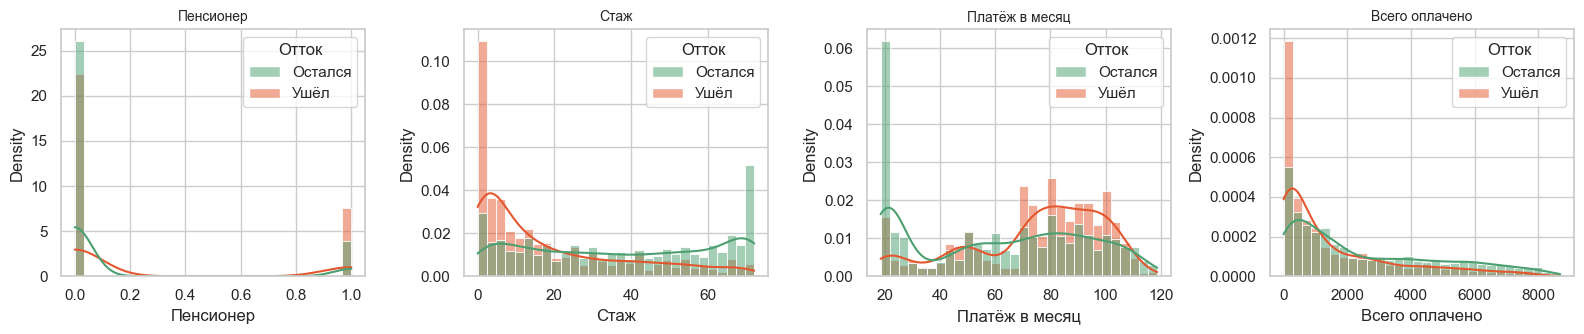

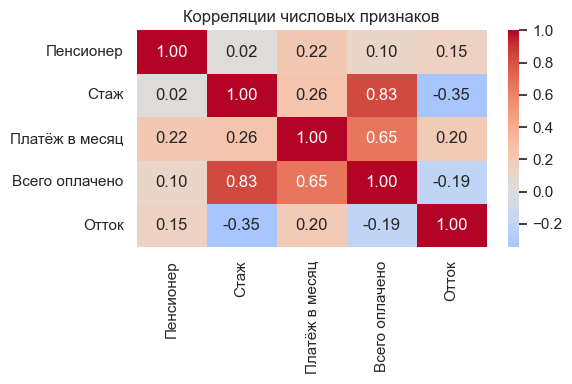

In [4]:
num_cols_all = [
    c for c in df_eda_raw.select_dtypes(include="number").columns
    if c != "Отток"
]

display(df_eda_raw[num_cols_all].describe().loc[["min", "25%", "50%", "75%", "max"]].T)

fig, axes = plt.subplots(1, len(num_cols_all), figsize=(4 * len(num_cols_all), 3.5), squeeze=False)
for ax, col in zip(axes[0], num_cols_all):
    sns.histplot(data=df_eda_raw, x=col, hue=df_eda_raw["Отток"].map(CLASS_LABELS), bins=30, stat="density",
                 common_norm=False, kde=True, palette=PALETTE, ax=ax)
    ax.set_title(col, fontsize=10)
plt.tight_layout()
plt.show()

corr = df_eda_raw[num_cols_all + ["Отток"]].corr()
plt.figure(figsize=(6, 4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Корреляции числовых признаков")
plt.tight_layout()
plt.show()


**Вывод:** распределения, аномалии и корреляции представлены на обучающей выборке. Интерпретацию численных значений следует сверять с графиками текущего запуска; тестовая выборка при анализе не использовалась.

### Проверяемые выводы EDA

Следующая ячейка выводит конкретные показатели **только для train**. Они дополняют графики распределений и корреляций и позволяют комиссии проверить исследовательские выводы.

In [5]:
# Проверяем конкретные выводы EDA только по обучающей выборке.
train_rate = df_eda_raw["Отток"].mean()
print(f"Доля оттока в train: {train_rate:.1%}")
print(f"Медианный стаж (train): {df_eda_raw['Стаж'].median():.0f} мес.")
print(f"Медианный ежемесячный платёж (train): {df_eda_raw['Платёж в месяц'].median():.2f}")
contract_rates = (df_eda_raw.groupby("Контракт", observed=True)["Отток"]
                  .agg(["mean", "size"]).sort_values("mean", ascending=False))
display(contract_rates.rename(columns={"mean":"Доля оттока", "size":"Клиентов"}))
print("Корреляция стажа с оттоком (train):",
      round(df_eda_raw[["Стаж", "Отток"]].corr().iloc[0,1], 3))
print("Вывод: сравнивайте долю оттока по типам контрактов и стажу; корреляция описывает связь, но не причинность.")


Доля оттока в train: 26.5%
Медианный стаж (train): 29 мес.
Медианный ежемесячный платёж (train): 70.50


,Доля оттока,Клиентов
Контракт,,
Помесячный,0.427466,3102
Годовой,0.110827,1173
Двухлетний,0.028698,1359


Корреляция стажа с оттоком (train): -0.346
Вывод: сравнивайте долю оттока по типам контрактов и стажу; корреляция описывает связь, но не причинность.


## Отток по сегментам и стажу (только train)
**Примечание к графику:** категории «Нет интернета» и «Нет телефонии» повторяются в нескольких столбцах услуг, поскольку это разные признаки с одинаковыми значениями. Повторение категорий не означает дублирование клиентов.


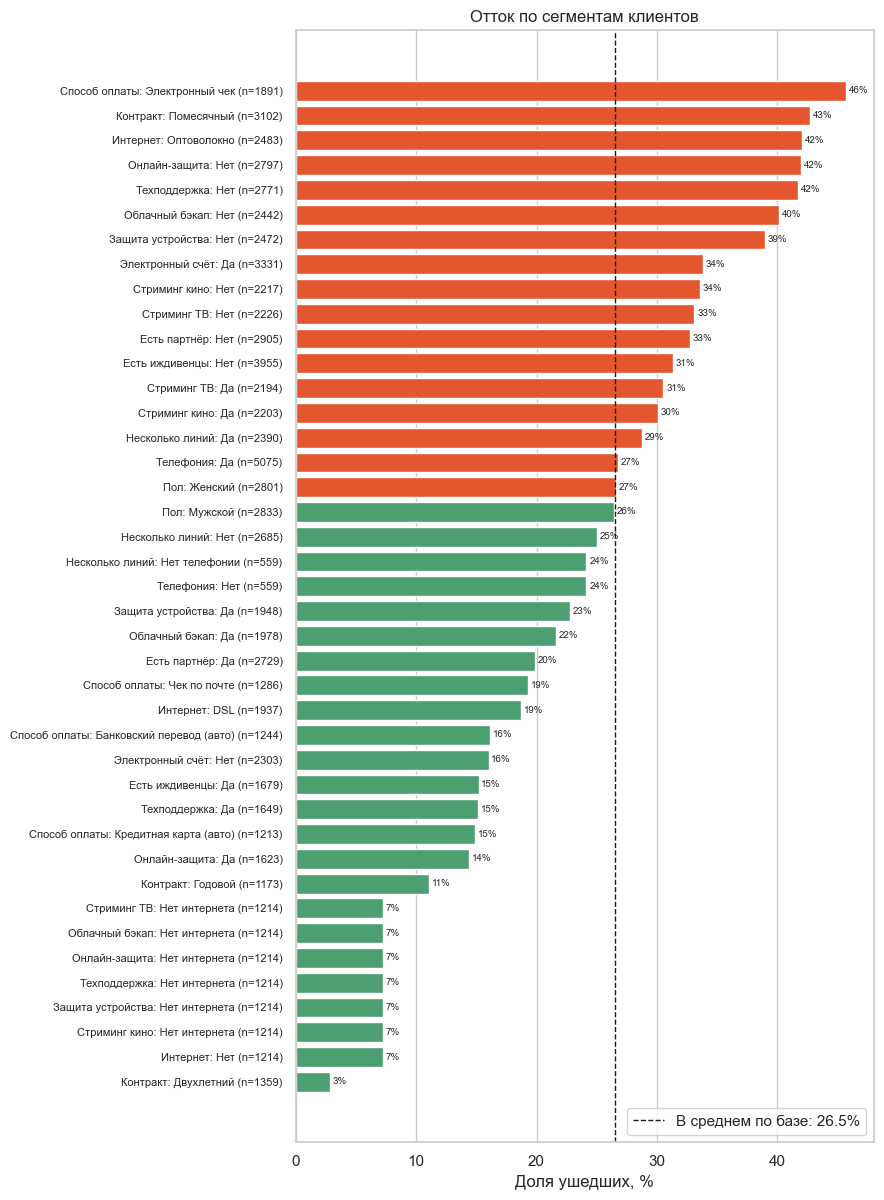

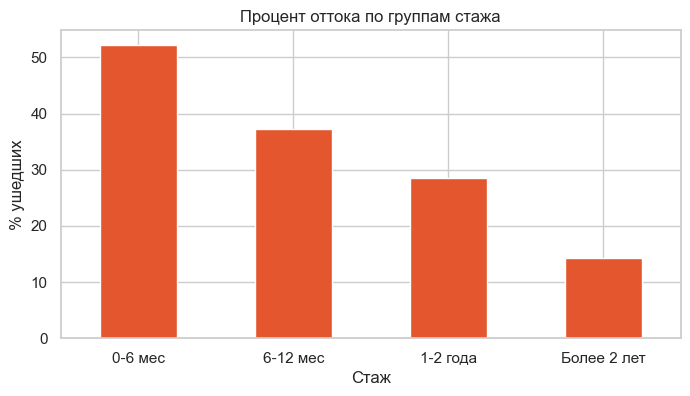

In [6]:
base = df_eda_raw["Отток"].mean() * 100
parts = []
for col in df_eda_raw.select_dtypes("category").columns:
    g = df_eda_raw.groupby(col, observed=True)["Отток"].agg(rate="mean", n="size")
    g.index = [f"{col}: {v} (n={n})" for v, n in zip(g.index, g["n"])]
    parts.append(g)

seg = pd.concat(parts).sort_values("rate")
seg["rate"] *= 100

fig, ax = plt.subplots(figsize=(9, 0.26 * len(seg) + 1.5))
ax.barh(seg.index, seg["rate"], color=np.where(seg["rate"] > base, PALETTE["Ушёл"], PALETTE["Остался"]))
ax.bar_label(ax.containers[0], fmt="%.0f%%", fontsize=7, padding=2)
ax.axvline(base, color="k", ls="--", lw=1, label=f"В среднем по базе: {base:.1f}%")
ax.set_xlabel("Доля ушедших, %")
ax.set_title("Отток по сегментам клиентов")
ax.legend(loc="lower right")
ax.tick_params(axis="y", labelsize=8)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

tenure_groups = pd.cut(df_eda_raw["Стаж"], bins=[-1, 6, 12, 24, 100],
                       labels=["0-6 мес", "6-12 мес", "1-2 года", "Более 2 лет"])
churn_by_tenure = df_eda_raw.groupby(tenure_groups, observed=True)["Отток"].mean() * 100
churn_by_tenure.plot(kind="bar", color="#e4572e", figsize=(8, 4))
plt.title("Процент оттока по группам стажа")
plt.ylabel("% ушедших")
plt.xticks(rotation=0)
plt.show()


### Выводы по EDA (только train)

1. **Тип контракта связан с оттоком:** для помесячных контрактов доля оттока **42,7%** (3 102 клиента), годовых — **11,1%** (1 173), двухлетних — **2,9%** (1 359). Это ассоциация, а не доказательство, что перевод на длительный контракт предотвратит уход.
2. **Стаж связан с оттоком отрицательно:** корреляция стажа с целевой переменной около **−0,346**; сегментные графики позволяют проверить концентрацию оттока среди новых клиентов.
3. **Оплата и интернет-услуги:** по сегментным графикам выделяются электронный чек и оптоволокно; эти связи могут отражать состав клиентских групп и не являются причинными эффектами.
4. **Проверяемые гипотезы:** платежи, количество услуг и наличие техподдержки могут быть полезными признаками; ниже они исследуются на train; оценка их полезности через ablation study запланирована на следующий этап.

**Ограничение:** показатели рассчитаны для сохранённого разбиения с `RANDOM_STATE=42`. При изменении исходных данных или разбиения выводы нужно обновить по фактическим таблицам.


## Новые признаки и проверка гипотез

Разделение на train/test выполнено **перед EDA и до** построения дополнительных признаков и их анализа. Исследование гипотез проводится только на train. Признаки рассчитываются построчно, без использования целевой переменной и агрегатов по выборке. Обучаемые преобразования (импутация, масштабирование, кодирование) остаются внутри `Pipeline` и оцениваются в CV без утечки статистик между фолдами.

В EDA выше показаны общие описательные графики; их нельзя использовать для выбора признаков/гиперпараметров после просмотра test. В этом ноутбуке весь целевой EDA проводится только на train.

Train: (5634, 23); Test: (1409, 23)


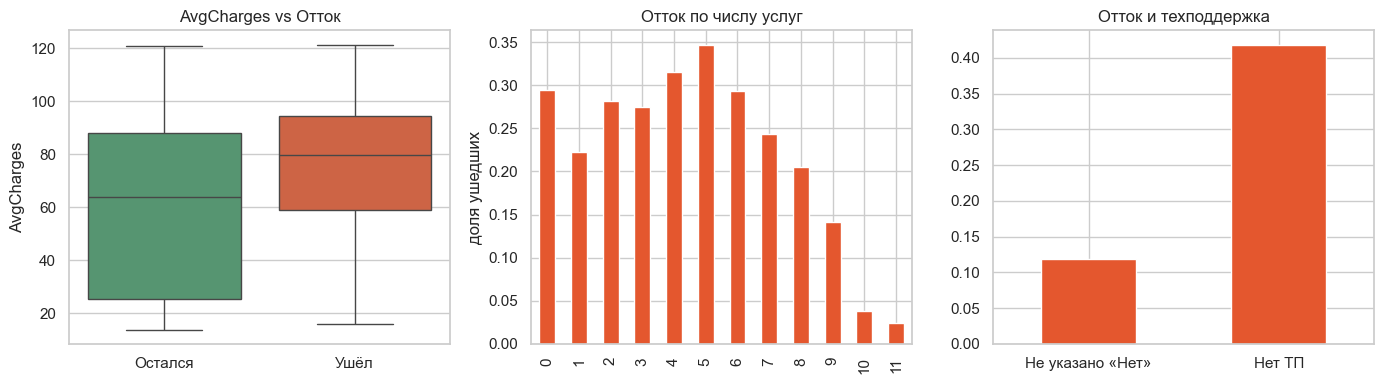

AvgCharges по классам (медиана / среднее):
        50%  mean
Отток            
0      64.0  61.4
1      79.8  74.9

Отток по числу услуг:
N_Services
0     0.294
1     0.223
2     0.282
3     0.275
4     0.316
5     0.346
6     0.294
7     0.244
8     0.206
9     0.141
10    0.038
11    0.024
Name: Отток, dtype: float64

Отток у клиентов без услуг (No_Services):
             Клиентов  Доля_оттока
No_Services                       
0                5617     0.265266
1                  17     0.294118

Отток при отсутствии техподдержки:
No_TechSupport
0    0.118
1    0.418
Name: Отток, dtype: float64
Проверка разделения после создания признаков: пройдена


In [7]:
# Train/Test уже разделены. Новые признаки считаются отдельно, исследование — только на train.
def find_col(*keywords):
    """Ищет столбец по фрагментам названия (для отчётов и демонстрации)."""
    for column in raw_X.columns:
        if all(word.lower() in column.lower() for word in keywords):
            return column
    raise KeyError(f"Нет столбца для {keywords}")

col_total = find_col("оплачено")
col_tenure = find_col("стаж")
service_cols = [c for c in raw_X.select_dtypes("category").columns
                if c not in ("Контракт", "Способ оплаты", "Интернет", "Пол")]
has_tech_support = any("поддерж" in c.lower() for c in raw_X.columns)
tech_col = find_col("поддерж") if has_tech_support else None

def engineer_features(frame):
    """Детерминированные построчные признаки; не использует y и статистики других строк."""
    result = frame.copy()
    result["AvgCharges"] = result[col_total] / result[col_tenure].replace(0, np.nan)
    result["N_Services"] = (result[service_cols] == "Да").sum(axis=1) if service_cols else 0
    result["No_Services"] = (result["N_Services"] == 0).astype(int)
    result["No_TechSupport"] = (result[tech_col] == "Нет").astype(int) if tech_col else 0
    return result

# Важно: test не участвует в исследовании гипотез и выборе признаков.
X_train = engineer_features(X_train_raw)
X_test = engineer_features(X_test_raw)
df_eda = X_train.copy()
df_eda["Отток"] = y_train
print(f"Train: {X_train.shape}; Test: {X_test.shape}")

fig, axes = plt.subplots(1, 3 if has_tech_support else 2, figsize=(14, 4))

sns.boxplot(data=df_eda, x=df_eda["Отток"].map(CLASS_LABELS), y="AvgCharges",
            hue=df_eda["Отток"].map(CLASS_LABELS), palette=PALETTE, legend=False, ax=axes[0])
axes[0].set_title("AvgCharges vs Отток")
axes[0].set_xlabel("")

df_eda.groupby("N_Services", observed=True)["Отток"].mean().plot.bar(color="#e4572e", ax=axes[1])
axes[1].set_title("Отток по числу услуг")
axes[1].set_ylabel("доля ушедших")
axes[1].set_xlabel("")

if has_tech_support:
    df_eda.groupby("No_TechSupport")["Отток"].mean().plot.bar(color="#e4572e", ax=axes[2])
    axes[2].set_title("Отток и техподдержка")
    axes[2].set_xticklabels(["Не указано «Нет»", "Нет ТП"], rotation=0)
    axes[2].set_xlabel("")

plt.tight_layout()
plt.show()

print("AvgCharges по классам (медиана / среднее):")
print(df_eda.groupby("Отток")["AvgCharges"].describe()[["50%", "mean"]].round(1))
print("\nОтток по числу услуг:")
print(df_eda.groupby("N_Services", observed=True)["Отток"].mean().round(3))
print("\nОтток у клиентов без услуг (No_Services):")
print(df_eda.groupby("No_Services")["Отток"].agg(Клиентов="size", Доля_оттока="mean").to_string())
if has_tech_support:
    print("\nОтток при отсутствии техподдержки:")
    print(df_eda.groupby("No_TechSupport")["Отток"].mean().round(3))

assert X_train.index.intersection(X_test.index).empty
assert len(X_train) + len(X_test) == len(df)
print("Проверка разделения после создания признаков: пройдена")


**Выводы по проверке гипотез на обучающей выборке (train):**

1. **AvgCharges:** медиана у ушедших клиентов **79,8**, у оставшихся — **64,0**; средние — **74,9** и **61,4** соответственно. Признак связан с оттоком в данном наборе данных, но это не доказывает, что увеличение платежа вызывает уход.

2. **N_Services и No_Services:** `No_Services = 1` означает отсутствие значений «Да» среди выбранных столбцов услуг, а не обязательно полное отсутствие услуг компании. В train таких клиентов 17; оценка оттока для них нестабильна.  связь с оттоком **немонотонная**. Доля оттока при нуле учитываемых услуг — **29,4%**, при четырёх — **31,6%**, при пяти — **34,6%**, при девяти — **14,1%**, при десяти — **3,8%**, при одиннадцати — **2,4%**. Категории с малым количеством клиентов могут давать нестабильные доли. Для проверки гипотезы в модель включены счётчик услуг и флаг их отсутствия; проверка полезности через ablation study запланирована на следующий этап.

3. **No_TechSupport:** доля оттока при отсутствии техподдержки — **41,8%**, при `No_TechSupport = 0` — **11,8%** (включая клиентов без интернета). Это выраженная ассоциация, но не доказательство того, что подключение поддержки само по себе снизит отток. Такую бизнес-гипотезу необходимо проверить отдельным экспериментом.

Показатели относятся к текущему разбиению (`RANDOM_STATE=42`); при изменении данных или разбиения их необходимо пересчитать.

## 3. Стратегия предобработки

- **Пропуски:** числовые — медианой (устойчива к выбросам), категориальные — самым частым значением.
  Пропуски в `AvgCharges` у новых клиентов со стажем 0 заполняем внутри пайплайна,
  чтобы медиана считалась только по train-фолду.
- **Кодирование:** OneHotEncoder — признаки номинальные, без порядка; `drop="if_binary"` не дублирует
  бинарные колонки; `handle_unknown="ignore"` не падает на редких категориях в test.
- **Масштабирование:** проверяем экспериментально в разделе 4.
- Всё объединяем в Pipeline: на каждом фолде предобработка обучается заново, что предотвращает утечку статистик между фолдами.


**Важно:** EDA носит описательный характер. Гипотезы изучаются на train. Построчные признаки не используют целевую переменную или статистики других клиентов.


*Числа в данном описании относятся к исследовательскому запуску; после изменения разбиения используйте выводы таблиц текущего запуска.*

In [8]:
# Разделение на train/test сделано ДО исследования дополнительных признаков (раздел 2).
# Предобработка с обучаемыми параметрами (imputer, scaler, OHE) остаётся внутри Pipeline.

cat_cols = X_train.select_dtypes("category").columns.tolist()
num_cols = X_train.select_dtypes("number").columns.tolist()

print(f"Категориальные ({len(cat_cols)}): {cat_cols}")
print(f"Числовые ({len(num_cols)}): {num_cols}")
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Категориальные (15): ['Пол', 'Есть партнёр', 'Есть иждивенцы', 'Телефония', 'Несколько линий', 'Интернет', 'Онлайн-защита', 'Облачный бэкап', 'Защита устройства', 'Техподдержка', 'Стриминг ТВ', 'Стриминг кино', 'Контракт', 'Электронный счёт', 'Способ оплаты']
Числовые (8): ['Пенсионер', 'Стаж', 'Платёж в месяц', 'Всего оплачено', 'AvgCharges', 'N_Services', 'No_Services', 'No_TechSupport']
Train: (5634, 23), Test: (1409, 23)


## Фабрики пайплайна

In [9]:
def make_preprocessor(scaler=None):
    """Единая фабрика препроцессора: imputers + опциональный scaler + OHE."""
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scaler is not None:
        num_steps.append(("scaler", scaler))
    cat_steps = [("imputer", SimpleImputer(strategy="most_frequent")),
                 ("ohe", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False))]
    return ColumnTransformer([
        ("cat", Pipeline(cat_steps), cat_cols),
        ("num", Pipeline(num_steps), num_cols),
    ])

def make_model(estimator, scaler=StandardScaler()):
    return Pipeline([("prep", make_preprocessor(scaler)), ("model", estimator)])


## 4. Сравнение способов масштабирования

Сравниваем четыре варианта на одинаковой 5-fold CV с логистической регрессией. Основной критерий — ROC-AUC; дополнительно контролируем сходимость. Нормы коэффициентов в разных масштабах не сравниваем как меры влияния признаков.

In [10]:
logreg = LogisticRegression(max_iter=5000, class_weight="balanced", random_state=RANDOM_STATE)

scaling_rows = []
for name, scaler in [("Без масштабирования", None), ("StandardScaler", StandardScaler()),
                     ("MinMaxScaler", MinMaxScaler()), ("RobustScaler", RobustScaler())]:
    pipe = make_model(logreg, scaler=scaler)
    # Несмасштабированная версия может не сходиться даже за 5000 итераций.
    # Явно фиксируем предупреждения вместо скрытия проблемы.
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", category=ConvergenceWarning)
        scores = cross_validate(pipe, X_train, y_train, cv=CV, scoring="roc_auc", n_jobs=1)
        pipe.fit(X_train, y_train)
    convergence_issues = sum(issubclass(w.category, ConvergenceWarning) for w in caught)
    if convergence_issues:
        print(f"{name}: {convergence_issues} предупреждений сходимости; не используйте эту версию для финальной модели")
    coefs = pipe.named_steps["model"].coef_[0]
    scaling_rows.append({"Способ": name,
                         "ROC-AUC (CV)": f"{scores['test_score'].mean():.4f} ± {scores['test_score'].std():.4f}",
                         "Число коэффициентов": len(coefs),
                         "||w||": round(np.linalg.norm(coefs), 1),
                         "max |w|": round(np.abs(coefs).max(), 1),
                         "Предупреждений сходимости": convergence_issues})
pd.DataFrame(scaling_rows).set_index("Способ")


Без масштабирования: 2 предупреждений сходимости; не используйте эту версию для финальной модели


,ROC-AUC (CV),Число коэффициентов,||w||,max |w|,Предупреждений сходимости
Способ,,,,,
Без масштабирования,0.8457 ± 0.0121,44,2.2,1.0,2
StandardScaler,0.8455 ± 0.0120,44,2.3,1.2,0
MinMaxScaler,0.8452 ± 0.0118,44,3.5,2.9,0
RobustScaler,0.8455 ± 0.0118,44,2.9,2.1,0


**Вывод по ★ масштабированию:** все четыре варианта оценивались на одинаковой 5-fold CV с одной LogisticRegression. ROC-AUC близка: без масштабирования **0,8457 ± 0,0121**, StandardScaler **0,8455 ± 0,0120**, MinMaxScaler **0,8452 ± 0,0118**, RobustScaler **0,8455 ± 0,0118**. Число коэффициентов одинаково (**44**), но их масштабы различаются: нормы `||w||` — **2,2 / 2,3 / 3,5 / 2,9** соответственно; максимальные модули коэффициентов — **1,0 / 1,2 / 2,9 / 2,1**. Без масштабирования получены **2 предупреждения сходимости**, у остальных вариантов — **0**. Поэтому для логистической регрессии оставлен **StandardScaler** как устойчивый и интерпретируемый вариант без потери качества. Коэффициенты моделей на разных шкалах нельзя напрямую сравнивать как эффекты исходных признаков.

## 5. Базовые модели

`DummyClassifier` — ориентир без использования информативных признаков, `LogisticRegression` — базовая обучаемая модель. Оцениваем ROC-AUC и Recall по пяти фолдам обучающей выборки; независимый Test не используется.

In [11]:
def cv_table(name, model):
    scores = cross_validate(model, X_train, y_train, cv=CV,
                            scoring={"roc_auc": "roc_auc", "recall": "recall"}, n_jobs=N_JOBS)
    return {"Модель": name,
            "ROC-AUC": f"{scores['test_roc_auc'].mean():.4f} ± {scores['test_roc_auc'].std():.4f}",
            "Recall": f"{scores['test_recall'].mean():.4f} ± {scores['test_recall'].std():.4f}"}

dummy = make_model(DummyClassifier(strategy="most_frequent"), scaler=None)
pipe_lr = make_model(logreg)

baseline_report = pd.DataFrame([
    cv_table("Dummy (most_frequent)", dummy),
    cv_table("LogisticRegression", pipe_lr),
]).set_index("Модель")
baseline_report

,ROC-AUC,Recall
Модель,,
Dummy (most_frequent),0.5000 ± 0.0000,0.0000 ± 0.0000
LogisticRegression,0.8455 ± 0.0120,0.8000 ± 0.0333


**Вывод по baseline:** `DummyClassifier(most_frequent)` даёт **ROC-AUC 0,5000 ± 0,0000**, **Recall 0**: он не находит ушедших. Простая LogisticRegression с StandardScaler достигает **ROC-AUC 0,8455 ± 0,0120** и **Recall 0,8000 ± 0,0333** на CV. Accuracy у Dummy была бы высокой из-за преобладания класса «остался», но не отражала бы способность выявлять отток.

## Промежуточные результаты и решения

- Проверено **7 043 записи**, доля оттока около **26,5%**. Совпадения по признакам не считаем доказанными ошибочными дубликатами.
- Анализируем зависимости **только на train**. В частности, видна связь оттока с типом контракта и стажем; это **ассоциации, не причинные эффекты**.
- Сформулированы гипотезы о среднем платеже, количестве услуг и техподдержке; созданные признаки требуют проверки в дальнейшем сравнении моделей.
- Предобработка построена через **Pipeline**, сравниваются четыре способа масштабирования. Для логистической регрессии выбран StandardScaler с учётом сходимости.
- **DummyClassifier: CV ROC-AUC 0,5000; LogisticRegression: 0,8455 ± 0,0120.** Это промежуточный baseline, а не итоговое качество проекта.

**Что не утверждаем на предзащите:** что уже выбрана лучшая модель, что достигнут бизнес-эффект, что результаты на независимом test уже представлены в этой сокращённой версии.

**План следующего этапа:** сравнить более сложные модели, подобрать гиперпараметры и порог классификации на обучающих данных, проверить вклад новых признаков, затем один раз оценить выбранную модель на независимом test и интерпретировать результаты.
